Optimized NanoTox models for cytotoxicity and cell viability

Author: Chi-Yun Chen; Supervisor: Zhoumeng Lin; 
Date created: Nov.17.2026

Description: Model performance and post-analyses. The best model files should be obtained in advance

RUN within 15 min

##Install necessary libraries

In [1]:
!pip install --upgrade pip
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [2]:
#Install basic python pcakges
import pandas as pd
import numpy as np
import seaborn as sns
import time

# Classification
Best model: Gradient Boost models

276 features (w/o further feature reduction)

In [3]:
Cytotox = pd.read_csv('Cytotox276_8831.csv')
Cytotox.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8831 entries, 0 to 8830
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Cytotoxicity       8831 non-null   object 
 1   Core               8831 non-null   object 
 2   Surf_func          8831 non-null   object 
 3   Assay_viability    8831 non-null   object 
 4   Cell_morphol       8831 non-null   object 
 5   Cell_type          8831 non-null   object 
 6   Tumor_cell         8831 non-null   int64  
 7   Cell_source        8831 non-null   object 
 8   Cell_culture       8831 non-null   int64  
 9   Cell_age           8831 non-null   int64  
 10  Diameter           8831 non-null   float64
 11  Time               8831 non-null   float64
 12  Concentration      8831 non-null   float64
 13  Mol_weight         8831 non-null   float64
 14  Electronegativity  8831 non-null   float64
 15  Dh_median          8831 non-null   float64
 16  ZP_median          8831 

In [4]:
CX = pd.read_csv('ClassX.csv')
CX.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8831 entries, 0 to 8830
Columns: 276 entries, Tumor_cell to Cell_source_Rat
dtypes: float64(7), int64(269)
memory usage: 18.6 MB


In [5]:
cY_2d = pd.read_csv('ClassY.csv')
cY_2d.info()
# Convert Y as a column vector to a 1D array
cY = cY_2d.values.ravel()
print(cY.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8831 entries, 0 to 8830
Data columns (total 1 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Cytotoxicity  8831 non-null   int64
dtypes: int64(1)
memory usage: 69.1 KB
(8831,)


In [6]:
# Install python pacakges
!pip install imblearn

Defaulting to user installation because normal site-packages is not writeable


In [7]:
import warnings
from scipy.stats import randint, uniform
from itertools import product
import matplotlib.pyplot as plt
import os
from joblib import load

## Best model import: GB

In [8]:
GB = load("Cytotox276_GB.joblib")

# Making predictions
y_pred_G = GB.predict(CX)

# Probability predictions (if needed)
y_prob_G = GB.predict_proba(CX)

In [9]:
Y_prop = Cytotox.loc[:, ['Core', 'Diameter', 'Surf_func', 'Assay_viability', 'Time', 'Concentration', 'Cell_type']]
Y_actual = cY_2d

# Ensure y_pred_X are DataFrames
y_pred_G = pd.Series(y_pred_G, name="Predicted")
# Convert y_prob_X_class_1 to a Pandas Series
y_prob_G_class_1 = pd.Series(y_prob_G[:, 1], name="Predict_Prob_Class_1")

# Concatenate the DataFrames
CytotoxG = pd.concat([Y_prop, Y_actual, y_pred_G, y_prob_G_class_1], axis=1)

In [10]:
# Rearrange 'CytotoxG' by the column 'Predict_Prob_Class_1' in ascending order
CytotoxG_sorted = CytotoxG.sort_values(by="Predict_Prob_Class_1", ascending=False)

# Reset the index if needed
CytotoxG_sorted = CytotoxG_sorted.reset_index(drop=True)

# Display the sorted DataFrame
print(CytotoxG_sorted)

      Core  Diameter   Surf_func Assay_viability  Time  Concentration  \
0     SiO2     30.00  Unmodified             MTS  24.0         1000.0   
1     SiO2     30.00  Unmodified    CellTiterGlo   2.0         1000.0   
2     MnO2     38.35  Unmodified             MTT  24.0          100.0   
3     SiO2     16.25  Unmodified           WST_1  72.0          500.0   
4     SiO2     24.00  Unmodified       Annexin_V  18.0         1000.0   
...    ...       ...         ...             ...   ...            ...   
8826  SiO2    200.00  Unmodified           WST_1  24.0            0.1   
8827   ZnO    141.00  Unmodified             MTT   3.0            1.0   
8828  TiO2      3.56  Unmodified             MTT   1.0            1.0   
8829   ZnO     61.59  Unmodified             MTT   1.0            1.0   
8830   ZnO      6.63  Unmodified             MTT   1.0            1.0   

              Cell_type  Cytotoxicity  Predicted  Predict_Prob_Class_1  
0              RAW264.7             1          1  

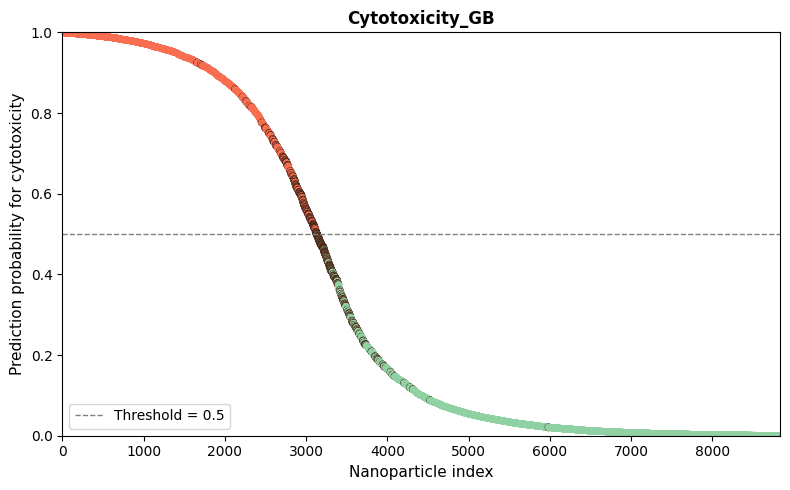

In [11]:
# Define colors based on the actual value 
# Red if actual value is 1, blue if actual value is 0
colors = ['#F96D51' if actual == 1 else '#8FD1A3' for actual in CytotoxG_sorted['Cytotoxicity']]

# Identify the indices where the actual and predicted values differ
Cdiff_indices = CytotoxG_sorted['Cytotoxicity'] != CytotoxG_sorted['Predicted']

# Create the plot
plt.figure(figsize=(8, 5))

# Scatter plot
plt.scatter(
    CytotoxG_sorted.index+1, 
    CytotoxG_sorted['Predict_Prob_Class_1'], 
    marker='o', c=colors, s=25, 
    edgecolors=np.where(Cdiff_indices, '#472417', 'none'),   # dark outline for differing points
    linewidths=0.7  
)

# Add horizontal dashed line for threshold
plt.axhline(y=0.5, color='gray', linestyle='--', linewidth=1, label="Threshold = 0.5")

# Set x and y axis ranges
plt.xlim(0, 8831)  
plt.ylim(0, 1)    

# Add labels and title
plt.xlabel("Nanoparticle index", fontsize=11)
plt.ylabel("Prediction probability for cytotoxicity", fontsize=11)
plt.title("Cytotoxicity_GB", fontweight="bold")
plt.legend(loc='lower left')

# Remove extra space before the axes
plt.tight_layout()

# Show the plot
plt.show()

In [12]:
summary = CytotoxG_sorted.groupby('Core').agg(
    both_positive=('Cytotoxicity', lambda x: ((x == 1) & (CytotoxG_sorted.loc[x.index, 'Predicted'] == 1)).sum()),
    both_negative=('Cytotoxicity', lambda x: ((x == 0) & (CytotoxG_sorted.loc[x.index, 'Predicted'] == 0)).sum()),
    cytotoxic_positive_predicted_negative=('Cytotoxicity', lambda x: ((x == 1) & (CytotoxG_sorted.loc[x.index, 'Predicted'] == 0)).sum()),
    cytotoxic_negative_predicted_positive=('Cytotoxicity', lambda x: ((x == 0) & (CytotoxG_sorted.loc[x.index, 'Predicted'] == 1)).sum()),
)
summary

,both_positive,both_negative,cytotoxic_positive_predicted_negative,cytotoxic_negative_predicted_positive
Core,,,,
Ag,1262,1359,49,49
Ag/Au,35,104,4,2
Al2O3,2,33,0,0
Au,50,295,6,0
Bi2O3,35,24,0,1
Ca10(PO4)6(OH)2,5,72,1,0
CeO2,0,22,0,0
Cu,4,4,0,0
CuO,51,43,0,1


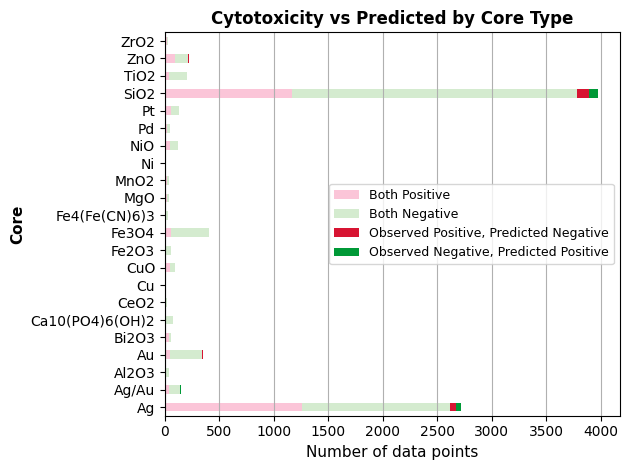

In [13]:
# Plotting
summary.plot(kind='barh', stacked=True, color=['#FBC5D8', '#D4EBCF', '#D71432', '#009937'])

plt.xlabel('Number of data points', fontsize=11)
plt.ylabel('Core', fontsize=11, fontweight="bold")
plt.title('Cytotoxicity vs Predicted by Core Type', fontweight="bold")
plt.legend(['Both Positive', 'Both Negative', 'Observed Positive, Predicted Negative', 'Observed Negative, Predicted Positive'], fontsize=9, loc='center right')
plt.grid(axis='x')
plt.tight_layout()

plt.show()

In [14]:
Cdiff_indices.value_counts()

False    8512
True      319
Name: count, dtype: int64

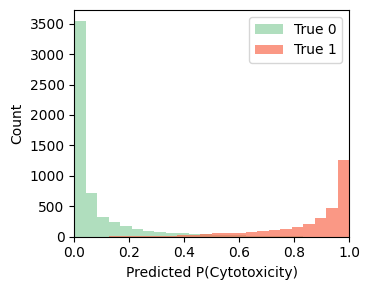

In [15]:
# a) create figure and axis
fig, ax = plt.subplots(figsize=(3.8, 3))

# b) define your bins and colors
bins   = np.linspace(0, 1, 25)
colors = {"Class 0": "#8FD1A3", "Class 1": "#F96D51"}

# c) get positive‐class probability from your fitted model instance
if hasattr(GB, "predict_proba"):
    prob_pos = GB.predict_proba(CX)[:, 1]
else:
    prob_pos = GB.predict(CX).ravel()

# d) split by true class
prob_class_0 = prob_pos[cY == 0]
prob_class_1 = prob_pos[cY == 1]

# e) plot histograms
ax.hist(prob_class_0, bins=bins, color=colors["Class 0"], alpha=0.7, label="True 0")
ax.hist(prob_class_1, bins=bins, color=colors["Class 1"], alpha=0.7, label="True 1")
ax.legend(loc="upper right")
ax.set_xlabel("Predicted P(Cytotoxicity)")
ax.set_ylabel("Count")

plt.xlim(0, 1)    
fig.tight_layout()

plt.show()

# External data evaluation

In [16]:
External = pd.read_csv('External1327.csv')
External.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1327 entries, 0 to 1326
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Cell_viability         1327 non-null   float64
 1   Cytotoxicity           1327 non-null   object 
 2   Core                   1327 non-null   object 
 3   Diameter               1327 non-null   float64
 4   Dh_median              1327 non-null   float64
 5   ZP_median              1327 non-null   float64
 6   Surf_func              1327 non-null   object 
 7   Assay_viability        1327 non-null   object 
 8   Test_indicator         1327 non-null   object 
 9   Time                   1327 non-null   int64  
 10  Concentration          1327 non-null   float64
 11  Cell_tissue            1327 non-null   object 
 12  Cell_age               1327 non-null   object 
 13  Cell_type              1327 non-null   object 
 14  Tumor_cell             1327 non-null   object 
 15  Cell

In [17]:
# remove 'Test_indicator', 'Cell_tissue', 'Cell_disease', 'Cell_viability'
cols_to_drop = External.columns[np.r_[0, 8, 11, 18, 21:30]]
External_cleaned = External.drop(columns=cols_to_drop)   

In [18]:
# Columns to be transformed via one-hot encoding
columns_to_encode = ["Core", "Surf_func", "Assay_viability", "Cell_morphol", "Cell_type", "Cell_source"]

# Perform one-hot encoding
External_encoded = pd.get_dummies(External_cleaned, columns=columns_to_encode, drop_first=True)

In [19]:
# Binary Encoding for columns with Number of unique values = 2 (reduce dimentionality)
External_encoded['Cell_age'] = External_encoded['Cell_age'].map({'Embryonic': 1, 'NonEmbryonic': 0})
External_encoded['Cell_culture'] = External_encoded['Cell_culture'].map({'primary': 1, 'cell_line': 0})
External_encoded['Tumor_cell'] = External_encoded['Tumor_cell'].map({'Yes': 1, 'No': 0})

# Map 'Non_cytotoxic' to 0 and 'Cytotoxic' to 1
External_encoded.iloc[:, 0] = External_encoded.iloc[:, 0].map({'Non_cytotoxic': 0, 'Cytotoxic': 1})

In [20]:
External_encoded.head()

,Cytotoxicity,Diameter,Dh_median,ZP_median,Time,Concentration,Cell_age,Tumor_cell,Cell_culture,Mol_weight,...,Cell_type_TR146,Cell_type_V79,Cell_type_Vero,Cell_type_hMSC,Cell_source_Dog,Cell_source_Hamster,Cell_source_Human,Cell_source_Monkey,Cell_source_Mouse,Cell_source_Rat
0,0,21.0,27.38,-10.2,24,2.0,0,1,0,79.865,...,False,False,False,False,False,False,True,False,False,False
1,0,21.0,27.38,-10.2,24,4.0,0,1,0,79.865,...,False,False,False,False,False,False,True,False,False,False
2,0,21.0,27.38,-10.2,24,6.0,0,1,0,79.865,...,False,False,False,False,False,False,True,False,False,False
3,0,21.0,27.38,-10.2,24,8.0,0,1,0,79.865,...,False,False,False,False,False,False,True,False,False,False
4,0,21.0,27.38,-10.2,24,10.0,0,1,0,79.865,...,False,False,False,False,False,False,True,False,False,False


In [21]:
# Converts True to 1 and False to 0 wherever they appear
External_encoded = External_encoded.map(lambda x: int(x) if isinstance(x, bool) else x)

In [22]:
ECY_2d = External_encoded.loc[:, ['Cytotoxicity']]
# Convert Y as a column vector to a 1D array
ECY = ECY_2d.values.ravel()
print(ECY.shape)

(1327,)


In [23]:
# X features
EX = External_encoded.iloc[:, 1:123]
print(EX.shape)

(1327, 122)


In [24]:
training_features = CX.columns   # Get column names from internal dataset

In [25]:
# Add all missing columns at once
missing_cols = list(set(training_features) - set(EX.columns))

missing_df = pd.DataFrame(
    0,
    index=EX.index,
    columns=missing_cols
)

EX = pd.concat([EX, missing_df], axis=1)

In [26]:
extra_cols = set(EX.columns) - set(training_features)

ECX = EX.drop(columns=extra_cols)

In [27]:
ECX = ECX[training_features]      #Reorder columns EXACTLY
ECX.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1327 entries, 0 to 1326
Columns: 276 entries, Tumor_cell to Cell_source_Rat
dtypes: float64(6), int64(270)
memory usage: 2.8 MB


# External data evaluation

In [28]:
# Prediction
Ey_pred = GB.predict(ECX)

# Probability predictions (if needed)
y_prob_EX = GB.predict_proba(ECX)

In [29]:
Y_prop = External.loc[:, ['Core', 'Cell_type', 'Time', 'Concentration', 'Surf_func']]
Y_actual = External_encoded.loc[:, ['Cytotoxicity']]

# Ensure Ey_pred are DataFrames
Ey_pred = pd.Series(Ey_pred, name="Predicted")
# Convert y_prob_EX_class_1 to a Pandas Series
y_prob_EX_class_1 = pd.Series(y_prob_EX[:, 1], name="Predict_Prob_Class_1")

# Concatenate the DataFrames
CytotoxEX = pd.concat([Y_prop, Y_actual, Ey_pred, y_prob_EX_class_1], axis=1)

In [30]:
# Create a grouping column based on whether new features exist
CytotoxEX['Index_Group'] = np.where(
    CytotoxEX.index <= 859,
    '0-859',         # no new features can be found from the first 693 data
    '860-1327'       # there are one or two new features introduced
)

CytotoxEX[CytotoxEX['Index_Group'] == '0-859']

,Core,Cell_type,Time,Concentration,Surf_func,Cytotoxicity,Predicted,Predict_Prob_Class_1,Index_Group
0,TiO2,HT29,24,2.0,Unmodified,0,0,0.002919,0-859
1,TiO2,HT29,24,4.0,Unmodified,0,0,0.006331,0-859
2,TiO2,HT29,24,6.0,Unmodified,0,0,0.013240,0-859
3,TiO2,HT29,24,8.0,Unmodified,0,0,0.020118,0-859
4,TiO2,HT29,24,10.0,Unmodified,0,0,0.023361,0-859
...,...,...,...,...,...,...,...,...,...
855,ZnO,MDCK,24,5.0,Unmodified,0,0,0.016192,0-859
856,ZnO,MDCK,24,10.0,Unmodified,0,0,0.198429,0-859
857,ZnO,MDCK,24,15.0,Unmodified,1,0,0.493708,0-859
858,ZnO,MDCK,24,30.0,Unmodified,1,1,0.839036,0-859


In [31]:
summary = CytotoxEX.groupby('Index_Group').agg(
    both_positive=('Cytotoxicity', lambda x: ((x == 1) & (CytotoxEX.loc[x.index, 'Predicted'] == 1)).sum()),
    both_negative=('Cytotoxicity', lambda x: ((x == 0) & (CytotoxEX.loc[x.index, 'Predicted'] == 0)).sum()),
    cytotoxic_positive_predicted_negative=('Cytotoxicity', lambda x: ((x == 1) & (CytotoxEX.loc[x.index, 'Predicted'] == 0)).sum()),
    cytotoxic_negative_predicted_positive=('Cytotoxicity', lambda x: ((x == 0) & (CytotoxEX.loc[x.index, 'Predicted'] == 1)).sum()),
)

summary

,both_positive,both_negative,cytotoxic_positive_predicted_negative,cytotoxic_negative_predicted_positive
Index_Group,,,,
0-859,146,517,134,63
860-1327,68,260,125,14


In [32]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score,  average_precision_score,
    matthews_corrcoef, confusion_matrix
)

# Function to calculate metrics
def calculate_metrics(group):
    y_true = group['Cytotoxicity']
    y_pred = group['Predicted']

    return pd.Series({
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_true, group['Predict_Prob_Class_1']),
        'PR AUC': average_precision_score(y_true, group['Predict_Prob_Class_1']),
        'MCC': matthews_corrcoef(y_true, y_pred),

        # Optional confusion matrix components
        'TN': confusion_matrix(y_true, y_pred).ravel()[0],
        'FP': confusion_matrix(y_true, y_pred).ravel()[1],
        'FN': confusion_matrix(y_true, y_pred).ravel()[2],
        'TP': confusion_matrix(y_true, y_pred).ravel()[3],
    })

# Create index groups
CytotoxEX['Index_Group'] = np.where(
    CytotoxEX.index <= 859,
    '0-859', '860-1327'
)

# Calculate metrics by group
metrics_summary = (
    CytotoxEX.groupby('Index_Group')[['Cytotoxicity', 'Predicted', 'Predict_Prob_Class_1']]
    .apply(calculate_metrics)
)

# Overall metrics
overall_metrics = calculate_metrics(CytotoxEX[['Cytotoxicity', 'Predicted', 'Predict_Prob_Class_1']])

# Add overall row
metrics_summary.loc['Overall'] = overall_metrics

# Round values for display
metrics_summary = metrics_summary.round(3)

print(metrics_summary)

             Accuracy  Precision  Recall  F1 Score  ROC AUC  PR AUC    MCC  \
Index_Group                                                                  
0-859           0.771      0.699   0.521     0.597    0.815   0.680  0.451   
860-1327        0.702      0.829   0.352     0.495    0.689   0.679  0.390   
Overall         0.747      0.735   0.452     0.560    0.760   0.670  0.419   

                TN    FP     FN     TP  
Index_Group                             
0-859        517.0  63.0  134.0  146.0  
860-1327     260.0  14.0  125.0   68.0  
Overall      777.0  77.0  259.0  214.0  


In [33]:
# Rearrange 'CytotoxEX' by the column 'Predict_Prob_Class_1' in ascending order
CytotoxEX_sorted = CytotoxEX.sort_values(by="Predict_Prob_Class_1", ascending=False)

# Reset the index if needed
CytotoxEX_sorted = CytotoxEX_sorted.reset_index(drop=True)

# Display the sorted DataFrame
print(CytotoxEX_sorted)

      Core Cell_type  Time  Concentration   Surf_func  Cytotoxicity  \
0      ZnO    Clone9    24    1000.000000       Fungi             1   
1      CuO  RAW264.7    24     200.000000  Unmodified             0   
2      ZnO      Vero    24    1000.000000       Fungi             1   
3     MnO2  RAW264.7    24      78.172264  Unmodified             1   
4     MnO2  RAW264.7    24      46.903358  Unmodified             1   
...    ...       ...   ...            ...         ...           ...   
1322  SiO2   EAHY926    48       0.500000      KG-1@C             0   
1323  SiO2   EAHY926    48       0.500000      Carbon             0   
1324   ZnO      A172     3       0.100000  Unmodified             0   
1325  SiO2   EAHY926    24       0.500000      Carbon             0   
1326  SiO2   EAHY926    24       0.500000      KG-1@C             0   

      Predicted  Predict_Prob_Class_1 Index_Group  
0             1              0.999508    860-1327  
1             1              0.999458      

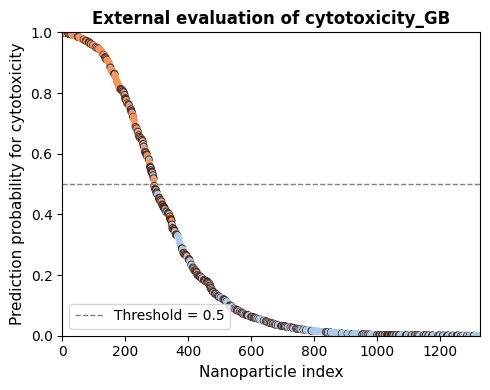

In [34]:
# Define colors based on the actual value
# Red if actual value is 1, blue if actual value is 0
colors = ['#F6955EFF' if actual == 1 else '#A8CDECFF' for actual in CytotoxEX_sorted['Cytotoxicity']]

# Identify the indices where the actual and predicted values differ
Cdiff_indices = CytotoxEX_sorted['Cytotoxicity'] != CytotoxEX_sorted['Predicted']

# Create the plot
plt.figure(figsize=(5, 4))

# Scatter plot
plt.scatter(
    CytotoxEX_sorted.index+1, 
    CytotoxEX_sorted['Predict_Prob_Class_1'], 
    marker='o', c=colors, s=25, 
    edgecolors=np.where(Cdiff_indices, '#472417', 'none'),   # dark outline for differing points
    linewidths=0.7  
)

# Add horizontal dashed line for threshold
plt.axhline(y=0.5, color='gray', linestyle='--', linewidth=1, label="Threshold = 0.5")

# Set x and y axis ranges
plt.xlim(0, 1327)  
plt.ylim(0, 1)    

# Add labels and title
plt.xlabel("Nanoparticle index", fontsize=11)
plt.ylabel("Prediction probability for cytotoxicity", fontsize=11)
plt.title("External evaluation of cytotoxicity_GB", fontweight="bold")
plt.legend(loc='lower left')

# Remove extra space before the axes
plt.tight_layout()

# Show the plot
plt.show()

In [35]:
summary = CytotoxEX_sorted.groupby('Core').agg(
    both_positive=('Cytotoxicity', lambda x: ((x == 1) & (CytotoxEX_sorted.loc[x.index, 'Predicted'] == 1)).sum()),
    both_negative=('Cytotoxicity', lambda x: ((x == 0) & (CytotoxEX_sorted.loc[x.index, 'Predicted'] == 0)).sum()),
    cytotoxic_positive_predicted_negative=('Cytotoxicity', lambda x: ((x == 1) & (CytotoxEX_sorted.loc[x.index, 'Predicted'] == 0)).sum()),
    cytotoxic_negative_predicted_positive=('Cytotoxicity', lambda x: ((x == 0) & (CytotoxEX_sorted.loc[x.index, 'Predicted'] == 1)).sum()),
)
summary

,both_positive,both_negative,cytotoxic_positive_predicted_negative,cytotoxic_negative_predicted_positive
Core,,,,
Ag,12,69,66,4
Au,0,86,36,0
Ca10(PO4)6(OH)2,0,0,8,0
CeO2,0,6,2,0
CuO,2,4,5,5
Fe3O4,0,40,13,1
Fe4(Fe(CN)6)3,0,22,1,4
MnO2,5,0,0,5
NiO,36,27,11,3


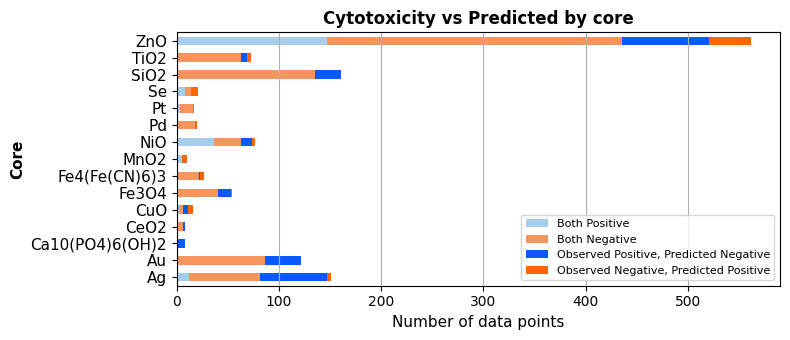

In [36]:
fig, ax = plt.subplots(figsize=(8, 3.5))

summary.plot(
    kind='barh',
    stacked=True,
    ax=ax,
    color=['#A8CDECFF', '#F6955EFF', '#085AFFFF', '#FF6600FF']
)

ax.set_xlabel('Number of data points', fontsize=11)
ax.set_ylabel('Core', fontsize=11, fontweight='bold')
ax.set_title('Cytotoxicity vs Predicted by core', fontweight='bold')
ax.tick_params(axis='y', labelsize=11)
ax.legend(
    ['Both Positive', 'Both Negative',
     'Observed Positive, Predicted Negative',
     'Observed Negative, Predicted Positive'],
    fontsize=8,
    loc='lower right'
)
ax.grid(axis='x')

fig.tight_layout()

plt.show()

In [37]:
Cdiff_indices.value_counts()

False    991
True     336
Name: count, dtype: int64

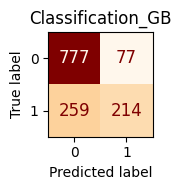

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay

# True and predicted labels
Y_actual
y_pred = CytotoxEX['Predicted']

# Compute confusion matrix
cm = confusion_matrix(Y_actual, y_pred)

# get the class labels in the order used by the model
labels = np.unique(Y_actual)

# Create display object
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

# Plot
fig, ax = plt.subplots(figsize=(2, 2))
disp.plot(ax=ax, cmap= "OrRd", colorbar=False, text_kw={"fontsize":12})  # cmap=plt.cm.Purple
ax.set_title("Classification_GB")
plt.tight_layout()

plt.show()

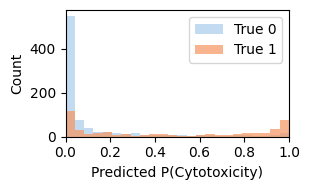

In [39]:
# a) create figure and axis
fig, ax = plt.subplots(figsize=(3.2, 2))

# b) define your bins and colors
bins   = np.linspace(0, 1, 25)
colors = {"Class 0": "#A8CDECFF", "Class 1": "#F6955EFF"}

# c) get positive‐class probability from your fitted model instance
if hasattr(GB, "predict_proba"):
    prob_pos = GB.predict_proba(ECX)[:, 1]
else:
    prob_pos = GB.predict(ECX).ravel()

# d) split by true class
prob_class_0 = prob_pos[ECY == 0]
prob_class_1 = prob_pos[ECY == 1]

# e) plot histograms
ax.hist(prob_class_0, bins=bins, color=colors["Class 0"], alpha=0.7, label="True 0")
ax.hist(prob_class_1, bins=bins, color=colors["Class 1"], alpha=0.7, label="True 1")
ax.legend(loc="upper right")
ax.set_xlabel("Predicted P(Cytotoxicity)")
ax.set_ylabel("Count")

plt.xlim(0, 1)    
fig.tight_layout()

plt.show()

## Feature importance analysis

In [40]:
!pip install pypalettes
from pypalettes import load_cmap
from pypalettes import create_cmap
import shap
from matplotlib.patches import Patch

Defaulting to user installation because normal site-packages is not writeable


## Feature importance analysis

In [41]:
# original vars
cat_vars = ['Core', 'Surf_func', 'Assay_viability', 'Cell_type', 'Cell_morphol', ' Cell_culture', 
            'Cell_source', 'Cell_age', 'Tumor_cell']
num_vars = ['Time', 'Concentration', 'Mol_weight', 'Electronegativity', 'Dh_median', 'ZP_median', 'Diameter']
# 1. compute SHAP
explainer = shap.Explainer(GB, CX)
shap_vals = explainer(CX).values        # (n_samples, n_onehot_features)
features  = CX.columns.tolist()

# 2. map each one-hot column back to its original var
def map_to_orig(feat):
    for c in cat_vars:
        if feat.startswith(f"{c}_"):
            return c
    if feat in num_vars:
        return feat
    return feat

mapping   = pd.Series(features, index=features).map(map_to_orig)

# 3. aggregate per‐sample SHAP by original var
shap_df    = pd.DataFrame(shap_vals, columns=features)
shap_aggr  = shap_df.T.groupby(mapping).sum().T

 97%|=================== | 8589/8831 [00:26<00:00]       

#SHAP Summary Plot: Features are ranked by their mean SHAP values, highlighting their overall importance.

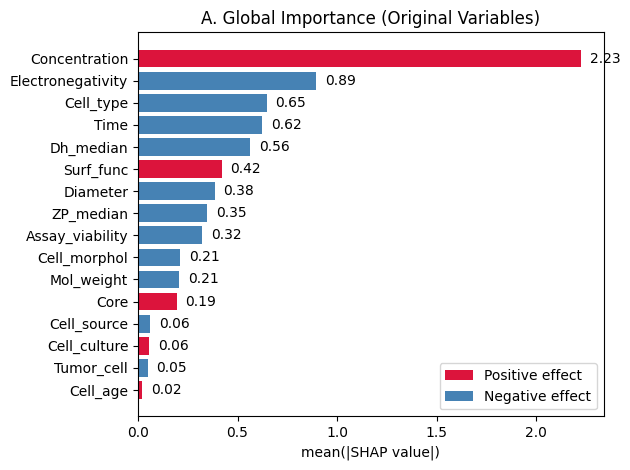

In [42]:
# 4. global importance on the aggregated vars
global_imp_agg = shap_aggr.abs().mean().sort_values(ascending=False)
global_mean_agg = shap_aggr.mean()  

# 5. assign color: red = positive effect, blue = negative effect
colors = ['crimson' if global_mean_agg[var] >= 0 else 'steelblue' 
          for var in global_imp_agg.index]

# — Plot A: Global attribute importance (aggregated vars) —
#plt.figure(figsize=(6,4))
plt.barh(global_imp_agg.index, global_imp_agg.values, color=colors)
plt.gca().invert_yaxis()
plt.title('A. Global Importance (Original Variables)')
plt.xlabel('mean(|SHAP value|)')
for i, v in enumerate(global_imp_agg.values):
    plt.text(v + global_imp_agg.max()*0.02, i, f"{v:.2f}", va='center')

# 6. add a legend
legend_elements = [Patch(facecolor='crimson',  label='Positive effect'),
                   Patch(facecolor='steelblue', label='Negative effect')]
plt.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()

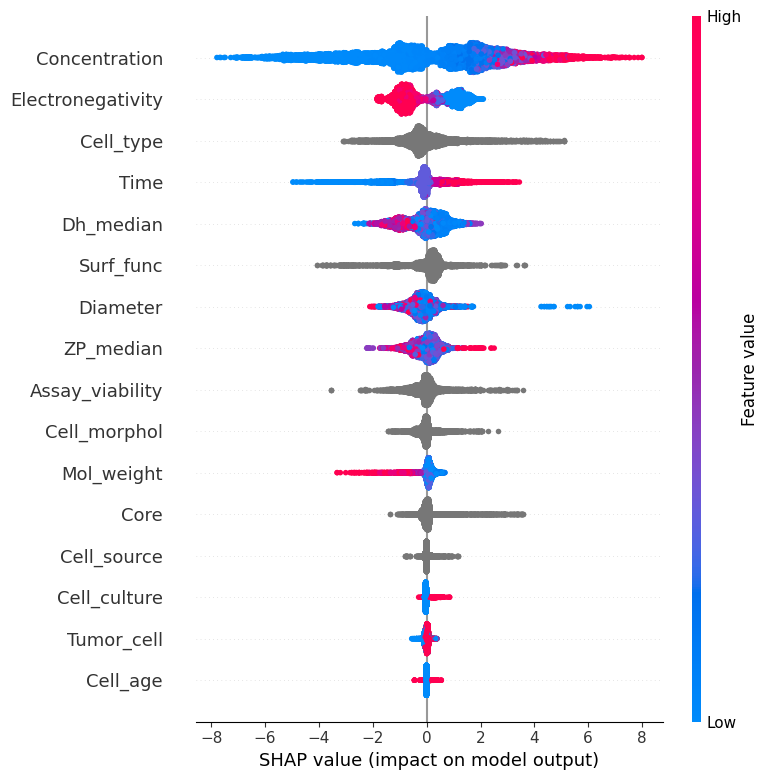

<Figure size 640x480 with 0 Axes>

In [43]:
# — Plot B: Local beeswarm for aggregated vars —
shap.summary_plot(
    shap_aggr.values,
    Cytotox[shap_aggr.columns], 
    feature_names=shap_aggr.columns.tolist(),
    plot_type='dot'
)
plt.tight_layout()
plt.show()

In [44]:
# build an Explanation for those variables
expl_agg = shap.Explanation(
  values=shap_aggr.values,
  base_values=explainer.expected_value,    # or whatever your baseline is
  data=Cytotox[shap_aggr.columns].values,
  feature_names=shap_aggr.columns.tolist()
)

/tmp/ipykernel_1724063/3726298535.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cax.set_yticklabels([f'{10**t:.3g}' for t in ticks])
/tmp/ipykernel_1724063/3726298535.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cax.set_yticklabels([f'{10**t:.3g}' for t in ticks])
/tmp/ipykernel_1724063/3726298535.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cax.set_yticklabels([f'{10**t:.3g}' for t in ticks])
/tmp/ipykernel_1724063/3726298535.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cax.set_yticklabels([f'{10**t:.3g}' for t in ticks])
/tmp/ipykernel_1724063/3726298535.py:26: UserWarning: set_ticklabels() should only be used with a fixed 

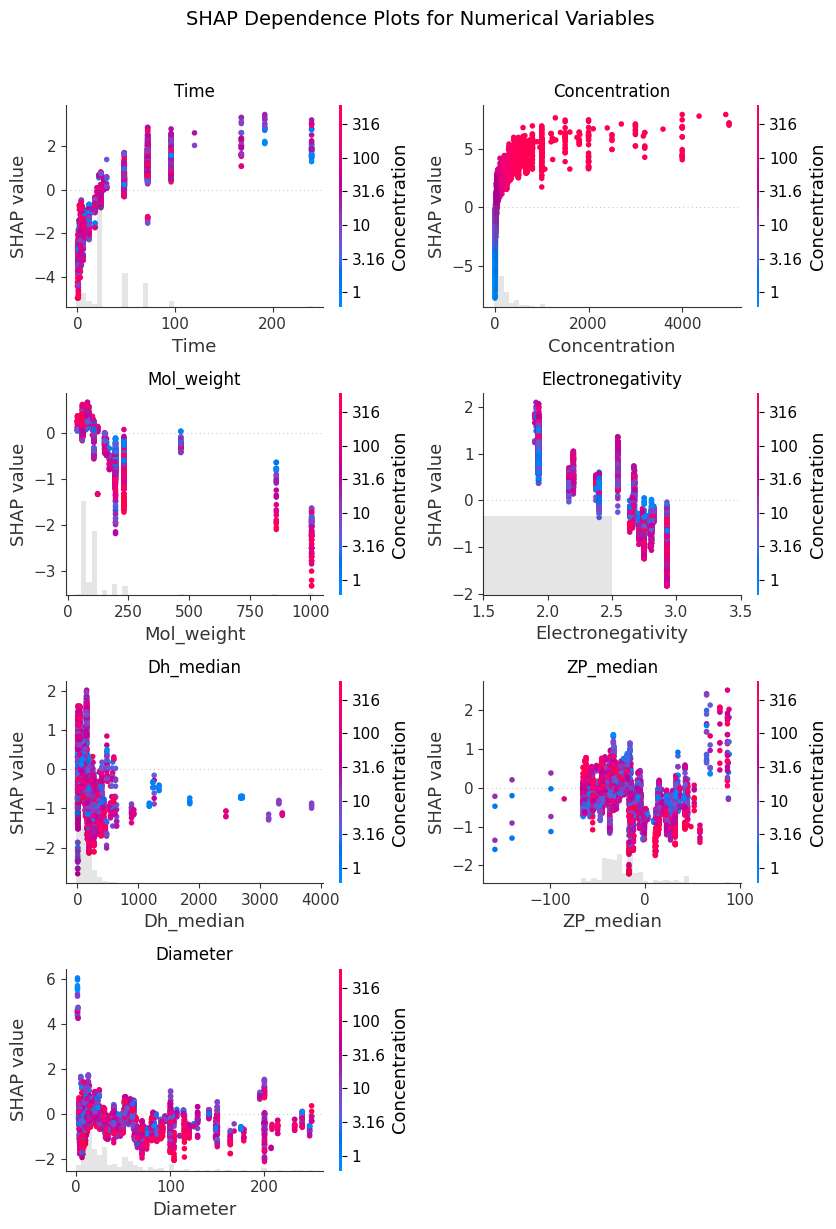

In [45]:
import copy

fig, axes = plt.subplots(4, 2, figsize=(8.5, 12))
axes = axes.flatten()

# log-transform concentration for coloring only (doesn't affect SHAP values/x-axis)
conc_log = copy.deepcopy(expl_agg[:, 'Concentration'])
conc_log.data = np.log10(conc_log.data.astype(float))

for i, var in enumerate(num_vars):
    n_axes_before = len(fig.axes)
    shap.plots.scatter(
        expl_agg[:, var],
        color=conc_log,
        ax=axes[i],
        show=False
    )
    axes[i].set_title(var)
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('SHAP value')

    # relabel the colorbar shap just created, converting log ticks back to real units
    new_axes = [a for a in fig.axes[n_axes_before:] if a not in axes]
    for cax in new_axes:
        ticks = cax.get_yticks()
        cax.set_yticklabels([f'{10**t:.3g}' for t in ticks])

for j in range(len(num_vars), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('SHAP Dependence Plots for Numerical Variables', fontsize=14, y=1.02)
plt.tight_layout()

plt.show()

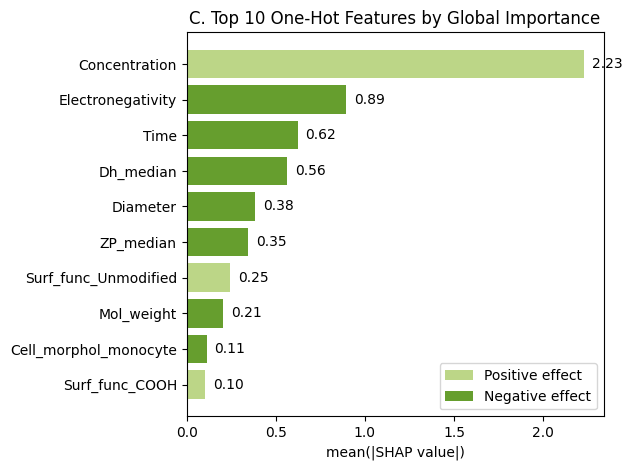

In [46]:
# 5. Now plot top-10 one-hot features globally
global_imp_onehot = pd.Series(
    np.abs(shap_vals).mean(axis=0),
    index=features
).sort_values(ascending=False)


# Signed mean (direction)
global_mean_onehot = pd.Series(
    shap_vals.mean(axis=0),
    index=features
)

top10_onehot = global_imp_onehot.head(10)

# Assign color by direction
colors = ['#BCD687' if global_mean_onehot[feat] >= 0 else '#669e2e'
          for feat in top10_onehot.index]

plt.barh(top10_onehot.index, top10_onehot.values, color=colors)
plt.gca().invert_yaxis()
plt.title('C. Top 10 One-Hot Features by Global Importance')
plt.xlabel('mean(|SHAP value|)')
for i, v in enumerate(top10_onehot.values):
    plt.text(v + top10_onehot.max()*0.02, i, f"{v:.2f}", va='center')
legend_elements = [Patch(facecolor='#BCD687', label='Positive effect'),
                   Patch(facecolor='#669e2e', label='Negative effect')]
plt.legend(handles=legend_elements, loc='lower right')    
plt.tight_layout()
plt.show()

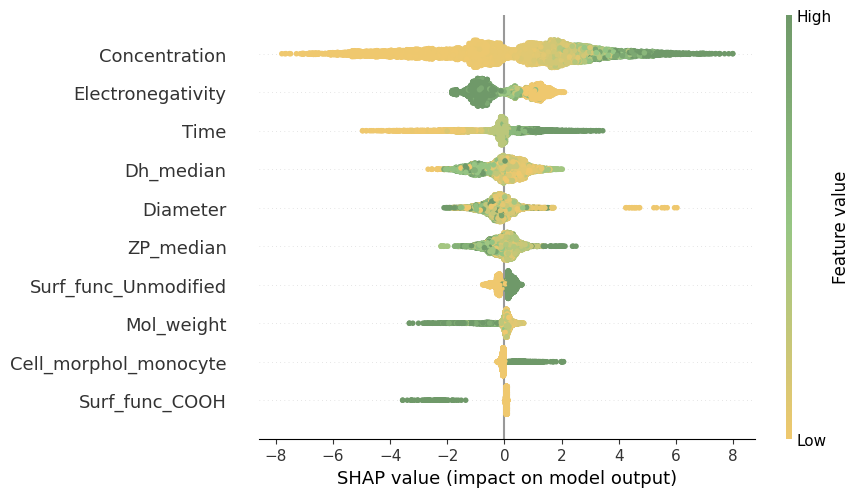

<Figure size 640x480 with 0 Axes>

In [47]:
# 6. pick out top-10 one-hot names & their integer positions
cols    = top10_onehot.index.tolist()
col_idx = [features.index(c) for c in cols]

# load the custom colormap
cmap = load_cmap("Derain", keep_first_n=3, cmap_type="continuous")
#cmap = load_cmap("Everglades", keep_first_n=4, cmap_type="continuous")
#cmap = load_cmap("Parupeneus_insularis", keep_first_n=2, cmap_type="continuous")
#cmap = load_cmap("Pastel", keep_first_n=2, cmap_type="continuous")

# build the Explanation object as before
expl_top10 = shap.Explanation(
    values=shap_vals[:, col_idx],
    base_values=explainer.expected_value,
    feature_names=cols,
    data=CX[cols].values
)

# pass it into the ‘color’ argument
shap.plots.beeswarm(
    expl_top10,
    max_display=10,
    color=cmap
)
plt.tight_layout()
plt.show()

#SHAP waterfall plot for a single prediction
showing how each feature’s SHAP value (the red/blue bars) shifts the model output from the baseline expectation (E[f(X)]) to the actual prediction f(x). 

In [48]:
CytotoxG_sorted.iloc[1830:1840]  #1835 

,Core,Diameter,Surf_func,Assay_viability,Time,Concentration,Cell_type,Cytotoxicity,Predicted,Predict_Prob_Class_1
1830,SiO2,70.00,NH2,MTS,24.0,600.00,HUVEC,1,1,0.905306
1831,Ag,43.00,Citrate,WST_1,24.0,10.00,T24,1,1,0.905184
1832,Ag/Au,8.50,PVP,MTT,5.0,100.00,HeLa,1,1,0.905142
1833,Ag,22.94,Betulin_PEG,MTT,72.0,10.80,HaCaT,1,1,0.905107
1834,Ag,10.00,Unmodified,MTT,48.0,200.00,B6MSC,1,1,0.905069
1835,SiO2,14.23,Unmodified,MTT,72.0,100.00,HepG2,1,1,0.904732
1836,Ag,200.00,Soybean_agglutinin/PEG,MTT,24.0,26.97,MCF7,1,1,0.904593
1837,SiO2,16.90,Unmodified,MTT,48.0,388.00,SHSY5Y,1,1,0.904495
1838,SiO2,20.00,L-arginine-R,CellTiterGlo,24.0,600.00,U373,1,1,0.904307
1839,Ag,15.00,Plant_extract,MTT,72.0,10.00,B16-F10,1,1,0.904307


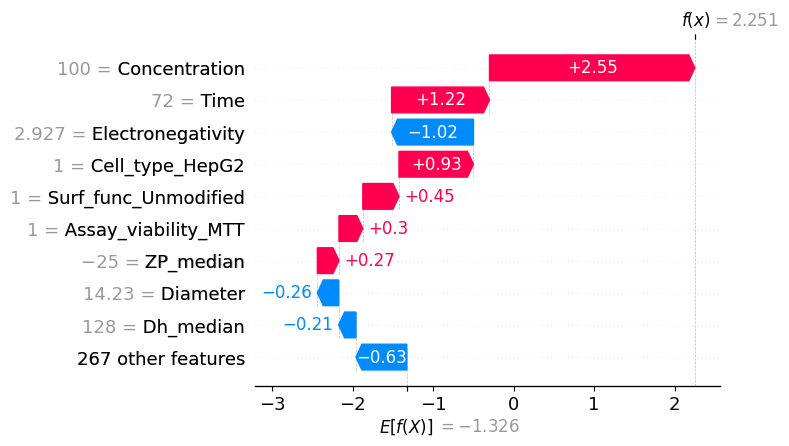

In [49]:
# pick a single example index:
# Gul et al. (2021)	2012	97	10.1016/j.taap.2011.12.020
i = 3892  # 1835 corresponding to #3892 in CX 

# build an Explanation for that one instance
expl_single = shap.Explanation(
    values      = shap_vals[i],               
    base_values = explainer.expected_value,   
    data        = CX.iloc[i].values,           
    feature_names = CX.columns.tolist()
)

# Create the SHAP waterfall plot without immediately showing it
shap.plots.waterfall(expl_single, max_display=10, show=False)

# Grab the current figure and save it to file
fig = plt.gcf()              
fig.set_size_inches(6, 4.5)

plt.show()

#SHAP decision plot, all participants: The SHAP values for all participants are summarized, demonstrating the overall feature contributions
A funnel-shaped overlay of every participant’s feature contributions, with one x-axis at the baseline and another at the final model output.

# Applicability domain

In [50]:
import matplotlib.gridspec as gridspec
from sklearn.ensemble import IsolationForest
from matplotlib.lines import Line2D
# ═══════════════════════════════════════════════════════════════════════
# 1.  LOAD MODEL + DATA
GB  = load("Cytotox276_GB.joblib")

# X_train_enc / X_test_enc as numpy arrays
X_train_enc = CX
X_test_enc  = ECX
y_train     = np.array(cY)
y_test      = np.array(ECY)

print("Model type:", type(GB).__name__)
print("X_train_enc:", np.asarray(X_train_enc).shape,
      " X_test_enc:", np.asarray(X_test_enc).shape,
      " model n_features_in_:", getattr(GB, "n_features_in_", None))
assert np.asarray(X_train_enc).shape[1] == np.asarray(X_test_enc).shape[1]
assert np.asarray(X_train_enc).shape[1] == getattr(GB, "n_features_in_", np.asarray(X_train_enc).shape[1])
n_train = len(X_train_enc)

# ═══════════════════════════════════════════════════════════════════════
# 2.  ISOLATION FOREST AD
iso = IsolationForest(contamination=0.05, n_estimators=100, max_samples=256, random_state=42)
iso.fit(X_train_enc)
iso_scores       = iso.score_samples(X_test_enc)
iso_train_scores = iso.score_samples(X_train_enc)
iso_in_domain    = iso.predict(X_test_enc) == 1

Model type: GradientBoostingClassifier
X_train_enc: (8831, 276)  X_test_enc: (1327, 276)  model n_features_in_: 276


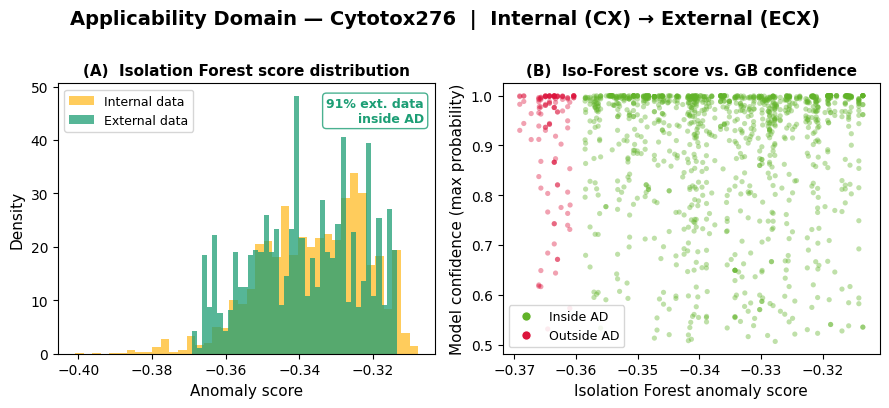

In [51]:
# 3. PLOT  (1 row × 2 cols) 
# (A) Iso-Forest dist  |  (B) CatBoost confidence 

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
fig.suptitle("Applicability Domain — Cytotox276  |  Internal (CX) → External (ECX)",
             fontsize=14, fontweight='bold', y=1.01)

# ── (A) Isolation Forest distribution  [Row1, Col1] ──────────────────
ax = axes[0]
ax.hist(iso_train_scores, bins=40, color="#FFCC5C",  label='Internal data', density=True)
ax.hist(iso_scores,       bins=40, alpha=0.75, color='#1D9E75', label='External data', density=True)
pct_in = iso_in_domain.sum() / len(y_test) * 100
ax.set_xlabel('Anomaly score', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.set_title('(A)  Isolation Forest score distribution', fontsize=11, fontweight='bold')
ax.legend(fontsize=9)
ax.text(0.97, 0.95, f'{pct_in:.0f}% ext. data\ninside AD',
        transform=ax.transAxes, ha='right', va='top', fontsize=9,
        color='#1D9E75', fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#1D9E75', alpha=0.8))
 
# ── Iso-Forest score vs. GB confidence  [Row1, Col2] ─────────────
ax = axes[1]
proba_GB = GB.predict_proba(X_test_enc).max(axis=1)
point_colors = np.where(iso_in_domain, "#61B329", "crimson")
ax.scatter(iso_scores, proba_GB, c=point_colors, alpha=0.4, s=14, linewidths=0)
ax.set_xlabel('Isolation Forest anomaly score', fontsize=11)
ax.set_ylabel('Model confidence (max probability)', fontsize=11)
ax.set_title('(B)  Iso-Forest score vs. GB confidence', fontsize=11, fontweight='bold')
ax.legend(handles=[
    Line2D([0],[0], marker='o', color='w', markerfacecolor="#61B329",  markersize=7, label='Inside AD'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor="crimson", markersize=7, label='Outside AD'),
], fontsize=9)

plt.tight_layout()

plt.show()

# Regression
Best model: XGB

In [52]:
Viability = pd.read_csv('Viability93_7012.csv')
Viability.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7012 entries, 0 to 7011
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Core                   7012 non-null   object 
 1   Test_indicator         7012 non-null   object 
 2   Cell_morphol           7012 non-null   object 
 3   Cell_disease           7012 non-null   object 
 4   Cell_source            7012 non-null   object 
 5   Cell_culture           7012 non-null   int64  
 6   Cell_tissue_GR         7012 non-null   object 
 7   Diameter               7012 non-null   float64
 8   Time                   7012 non-null   float64
 9   Concentration          7012 non-null   float64
 10  Mol_weight             7012 non-null   float64
 11  Electronegativity      7012 non-null   float64
 12  is_Unmodified          7012 non-null   int64  
 13  is_Biological          7012 non-null   int64  
 14  is_PEG_Polymer         7012 non-null   int64  
 15  is_F

In [53]:
rX = pd.read_csv('Regress_X.csv')
rX.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7012 entries, 0 to 7011
Data columns (total 93 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Cell_culture                        7012 non-null   int64  
 1   Diameter                            7012 non-null   float64
 2   Time                                7012 non-null   float64
 3   Concentration                       7012 non-null   float64
 4   Mol_weight                          7012 non-null   float64
 5   Electronegativity                   7012 non-null   float64
 6   is_Unmodified                       7012 non-null   int64  
 7   is_Biological                       7012 non-null   int64  
 8   is_PEG_Polymer                      7012 non-null   int64  
 9   is_FuncGroup                        7012 non-null   int64  
 10  is_Silica_Inorganic                 7012 non-null   int64  
 11  is_Lipid_Bile_Acid                  7012 no

In [54]:
rY_2d = pd.read_csv('Regress_Y.csv')
# Convert Y as a column vector to a 1D array
rY = rY_2d.values.ravel()
print(rY.shape)

(7012,)


In [55]:
XGBV = load("Viability93_XGB.joblib")

# Making predictions
y_pred_cv = np.clip(XGBV.predict(rX), 0, 120)

In [56]:
V_actual = Viability.loc[:, ['Core', 'Diameter', 'Cell_tissue_GR', 'Electronegativity', 'Concentration']]
# Reset the index before concatenation
V_sorted = V_actual.reset_index(drop=True)

# Ensure y_pred_cv is DataFrame
y_pred_cv = pd.Series(y_pred_cv, name="Predicted")

# Concatenate the DataFrames
rY = pd.Series(rY, name="Actual")

ViabilityX = pd.concat([V_sorted, rY, y_pred_cv], axis=1)

In [57]:
# Rearrange 'ViabilityX' by the column 'Predicted' in ascending order
ViabilityX_sorted = ViabilityX.sort_values(by="Predicted", ascending=False)

# Display the sorted DataFrame
print(ViabilityX_sorted)

      Core  Diameter Cell_tissue_GR  Electronegativity  Concentration  \
5398    Ag    129.00           Skin           1.930000          25.00   
6812    Au     20.58   Abdominal_GI           2.400000         100.00   
197   SiO2     12.00   Abdominal_GI           2.926667         300.00   
6943   ZnO     25.59   Abdominal_GI           2.545000         100.00   
6942   ZnO     25.59   Abdominal_GI           2.545000         100.00   
...    ...       ...            ...                ...            ...   
6239    Ag     40.00         Breast           1.930000          25.00   
4167    Ag     29.57   Reproductive           1.930000          15.00   
4168    Ag     29.57   Reproductive           1.930000          20.00   
2837   CuO     30.09     BoneMarrow           2.670000         100.00   
5090    Ag      3.89         Breast           1.930000          37.75   

          Actual  Predicted  
5398  120.000000      120.0  
6812  120.000000      120.0  
197   120.000000      120.0  
694

In [58]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

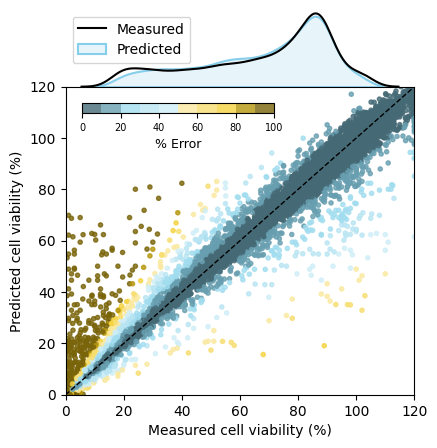

In [59]:
# Data
x = ViabilityX["Actual"]      # Measured
y = ViabilityX["Predicted"]   # predicted
percent_error = np.abs((y - x) / x) * 100

# Set up grid: scatter bottom, density top, colorbar on side
fig = plt.figure(figsize=(5, 5))
grid = plt.GridSpec(5, 20, hspace=0.0, wspace=0.05)  # no vertical gap

ax_kde = fig.add_subplot(grid[0, 0:18], sharex=None) # KDE on top
ax_scatter = fig.add_subplot(grid[1:, 0:18])         # scatter below
#ax_cbar = fig.add_subplot(grid[1:, 19])              # colorbar

# === Scatter ===
sc = ax_scatter.scatter(
    x, y,
    c=percent_error,
    cmap = load_cmap("dPBIYlBu", reverse=True,
                     keep=[True, True, True, True, True, False, True, True, True, True, True]
                    ),
    s=9, alpha=0.8, 
    vmin=0, vmax=100
)

# 1:1 diagonal line
lims = [0, 120]
ax_scatter.plot(lims, lims, 'k--', linewidth=1)
ax_scatter.set_xlim(0, 120)
ax_scatter.set_ylim(0, 120)

ax_scatter.set_xlabel("Measured cell viability (%)")
ax_scatter.set_ylabel("Predicted cell viability (%)")

# === Density on top (stuck to scatter) ===
sns.kdeplot(x=x, ax=ax_kde, color="black", linewidth=1.5, fill=False, label="Measured")
sns.kdeplot(x=y, ax=ax_kde, color="skyblue", linewidth=1.5, fill=True, alpha=0.2, label="Predicted")

# Remove all frame + ticks from KDE plot
ax_kde.set_frame_on(False)
ax_kde.get_xaxis().set_visible(False)
ax_kde.get_yaxis().set_visible(False)

# Put legend inside scatter instead
ax_kde.legend(loc="upper left")

# === Colorbar inset in lower right of scatter ===
axins = inset_axes(
    ax_scatter,
    width="55%",   # width of colorbar relative to ax_scatter
    height="3%",   # height
    loc="upper left",
    borderpad=1.2
)
cbar = fig.colorbar(sc, cax=axins, orientation="horizontal")
cbar.set_label("% Error", fontsize=9)
cbar.ax.tick_params(labelsize=7)

plt.show()

Parity plot of predicted against calculated viability together with a histogram of predicted and calculated  distributions.

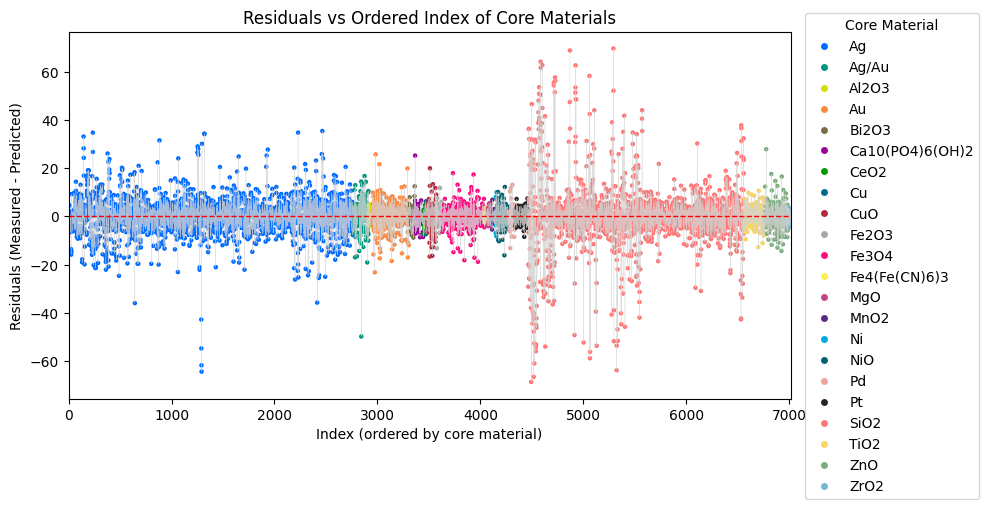

In [60]:
# 1. Compute residuals
ViabilityXR = ViabilityX.copy()
ViabilityXR['Residuals'] = ViabilityXR['Actual'] - ViabilityXR['Predicted']

# 2. Reset index by the order of core materials (alphabetically)
ViabilityXR = ViabilityXR.sort_values(by='Core').reset_index(drop=True)

# 3. Make color palette (19 distinct colors)
unique_materials = ViabilityXR['Core'].unique()
cmap = create_cmap(
    colors=['#006BFFFF', '#00957EFF', '#D0E005FF', '#FD873EFF', '#7C6D46FF',   # Coris_gaimard
            '#990099FF', '#009900FF',                                          # classic
            '#006A8EFF', '#B1283AFF', '#A8A6A7FF',                             # wsj_dem_rep
            '#FD0C81FF', '#FFED4DFF', '#C34582FF', '#582C83FF', '#00A9E0FF', '#006271FF', '#EBA49EFF', '#272324FF', #"AndyWarhol_1" mixed "jazz_classic"
            '#FF7676FF', '#F9D662FF', '#7CAB7DFF', '#75B7D1FF']                # fernande
) 
color_map = {t: cmap(i) for i, t in enumerate(unique_materials)}

# 4. Plot scatter with lines
plt.figure(figsize=(10,5))
plt.scatter(ViabilityXR.index, ViabilityXR['Residuals'], c=ViabilityXR['Core'].map(color_map), label='Residuals', s=5)
plt.plot(ViabilityXR.index, ViabilityXR['Residuals'], color='lightgray', alpha=0.8, linewidth=0.3)  # connecting line

# 5. Formatting
plt.axhline(y=0, color='red', linestyle='--', linewidth=1)  # reference line
plt.xlim(0, 7013)
# Add legend for core materials
handles = [plt.Line2D([0], [0], marker='o', color='w',
                      markerfacecolor=color_map[m], markersize=6)
           for m in unique_materials]
plt.legend(handles, unique_materials, title="Core Material", bbox_to_anchor=(1.01, 1.07), loc='upper left')

plt.xlabel("Index (ordered by core material)")
plt.ylabel("Residuals (Measured - Predicted)")
plt.title("Residuals vs Ordered Index of Core Materials")
plt.tight_layout()

plt.show()

# External data evaluation

In [61]:
External.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1327 entries, 0 to 1326
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Cell_viability         1327 non-null   float64
 1   Cytotoxicity           1327 non-null   object 
 2   Core                   1327 non-null   object 
 3   Diameter               1327 non-null   float64
 4   Dh_median              1327 non-null   float64
 5   ZP_median              1327 non-null   float64
 6   Surf_func              1327 non-null   object 
 7   Assay_viability        1327 non-null   object 
 8   Test_indicator         1327 non-null   object 
 9   Time                   1327 non-null   int64  
 10  Concentration          1327 non-null   float64
 11  Cell_tissue            1327 non-null   object 
 12  Cell_age               1327 non-null   object 
 13  Cell_type              1327 non-null   object 
 14  Tumor_cell             1327 non-null   object 
 15  Cell

In [62]:
External_cleaned = External.drop(columns=External.columns[[1, 7, 6, 11, 12, 14]])

In [63]:
# Columns to be transformed via one-hot encoding
columns_to_encode = ["Core", "Test_indicator", "Cell_tissue_GR", "Cell_source", "Cell_morphol", "Cell_disease"]

# Perform one-hot encoding
External_encoded = pd.get_dummies(External_cleaned, columns=columns_to_encode, drop_first=True)

In [64]:
# Binary Encoding for columns with Number of unique values = 2 (reduce dimentionality)
External_encoded['Cell_culture'] = External_encoded['Cell_culture'].map({'primary': 1, 'cell_line': 0})

In [65]:
External_encoded.head()

,Cell_viability,Diameter,Dh_median,ZP_median,Time,Concentration,Cell_type,Cell_culture,Mol_weight,Electronegativity,...,Cell_morphol_microglia,Cell_morphol_monocyte,Cell_morphol_neuronal,Cell_disease_glioblastoma,Cell_disease_leukemia,Cell_disease_lymphoma,Cell_disease_melanoma,Cell_disease_neuroblastoma,Cell_disease_normal,Cell_disease_rheumatoid arthritis
0,91.926529,21.0,27.38,-10.2,24,2.0,HT29,0,79.865,2.806667,...,False,False,False,False,False,False,False,False,False,False
1,85.551919,21.0,27.38,-10.2,24,4.0,HT29,0,79.865,2.806667,...,False,False,False,False,False,False,False,False,False,False
2,80.701673,21.0,27.38,-10.2,24,6.0,HT29,0,79.865,2.806667,...,False,False,False,False,False,False,False,False,False,False
3,77.375789,21.0,27.38,-10.2,24,8.0,HT29,0,79.865,2.806667,...,False,False,False,False,False,False,False,False,False,False
4,74.049906,21.0,27.38,-10.2,24,10.0,HT29,0,79.865,2.806667,...,False,False,False,False,False,False,False,False,False,False


In [66]:
# Converts True to 1 and False to 0 wherever they appear
External_encoded = External_encoded.map(lambda x: int(x) if isinstance(x, bool) else x)

In [67]:
ERY_2d = External_encoded.loc[:, ['Cell_viability']]
# Convert Y as a column vector to a 1D array
ERY = ERY_2d.values.ravel()
print(ERY.shape)

ERY = np.clip(ERY, a_min=None, a_max=120)  #  Cap viability at 120%

(1327,)


In [68]:
# X features
EX = External_encoded.drop(columns=['Cell_viability'])
print(EX.shape)

(1327, 77)


In [69]:
training_features = rX.columns   # Get column names from internal dataset

In [70]:
# Add all missing columns at once
missing_cols = list(set(training_features) - set(EX.columns))

missing_df = pd.DataFrame(
    0,
    index=EX.index,
    columns=missing_cols
)

EX = pd.concat([EX, missing_df], axis=1)

In [71]:
extra_cols = set(EX.columns) - set(training_features)

ERX = EX.drop(columns=extra_cols)

In [72]:
ERX = ERX[training_features]      #Reorder columns EXACTLY
ERX.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1327 entries, 0 to 1326
Data columns (total 93 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Cell_culture                        1327 non-null   int64  
 1   Diameter                            1327 non-null   float64
 2   Time                                1327 non-null   int64  
 3   Concentration                       1327 non-null   float64
 4   Mol_weight                          1327 non-null   float64
 5   Electronegativity                   1327 non-null   float64
 6   is_Unmodified                       1327 non-null   int64  
 7   is_Biological                       1327 non-null   int64  
 8   is_PEG_Polymer                      1327 non-null   int64  
 9   is_FuncGroup                        1327 non-null   int64  
 10  is_Silica_Inorganic                 1327 non-null   int64  
 11  is_Lipid_Bile_Acid                  1327 no

**Prediction**

In [73]:
# Prediction
Ey_pred = np.clip(XGBV.predict(ERX), 0, 120)

V_actual = External.loc[:, ['Core', 'Diameter', 'Concentration', 'Cell_disease']]
# Reset the index
V_sorted = V_actual.reset_index(drop=True)

# Ensure y_pred_G is DataFrame
Ey_pred = pd.Series(Ey_pred, name="Predicted")

# Concatenate the DataFrames
ERY = pd.Series(ERY, name="Actual")
ViabilityXGB = pd.concat([V_sorted, ERY, Ey_pred], axis=1)

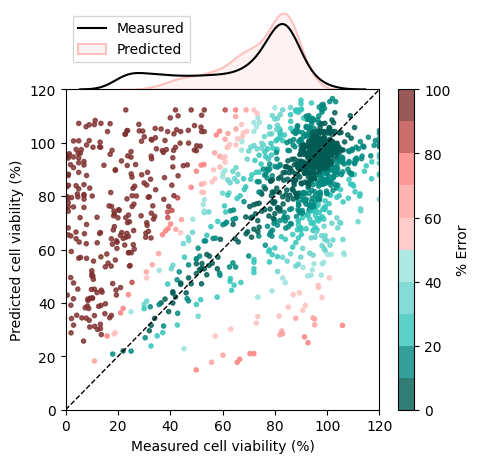

In [74]:
# Data
x = ViabilityXGB["Actual"]      # Measured
y = ViabilityXGB["Predicted"]   # predicted
percent_error = np.abs((y - x) / x) * 100

# Set up grid: scatter bottom, density top, colorbar on side
fig = plt.figure(figsize=(4.5, 5.2))
grid = plt.GridSpec(5, 20, hspace=0.0, wspace=0.05)  # no vertical gap

ax_kde = fig.add_subplot(grid[0, 0:18], sharex=None) # KDE on top
ax_scatter = fig.add_subplot(grid[1:, 0:18])         # scatter below
ax_cbar = fig.add_subplot(grid[1:, 19])              # colorbar

# === Scatter ===
sc = ax_scatter.scatter(
    x, y,
    c=percent_error,
    cmap = load_cmap("dPBIRdGn", reverse=True,
                     keep=[True, True, True, True, True, False, True, True, True, True, True]
                    ),
    s=9, alpha=0.8, 
    vmin=0, vmax=100
)

# 1:1 diagonal line
lims = [0, 120]
ax_scatter.plot(lims, lims, 'k--', linewidth=1)
ax_scatter.set_xlim(0, 120)
ax_scatter.set_ylim(0, 120)

ax_scatter.set_xlabel("Measured cell viability (%)")
ax_scatter.set_ylabel("Predicted cell viability (%)")

# === Density on top (stuck to scatter) ===
sns.kdeplot(x=x, ax=ax_kde, color="black", linewidth=1.5, fill=False, label="Measured")
sns.kdeplot(x=y, ax=ax_kde, color="#FFC0C0", linewidth=1.5, fill=True, alpha=0.2, label="Predicted")   

# Remove all frame + ticks from KDE plot
ax_kde.set_frame_on(False)
ax_kde.get_xaxis().set_visible(False)
ax_kde.get_yaxis().set_visible(False)

# Put legend inside scatter instead
ax_kde.legend(loc="upper left")

# === Color bar ===
cbar = fig.colorbar(sc, cax=ax_cbar)
cbar.set_label("% Error")

plt.show()

In [75]:
from sklearn.metrics import (r2_score, mean_squared_error,
    mean_absolute_error)
from scipy.stats import spearmanr

# True and predicted values
y_true = ViabilityXGB['Actual'].values
y_pred = ViabilityXGB['Predicted'].values

# --- Existing metrics ---
r2   = r2_score(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)
rho, p = spearmanr(y_true, y_pred)

# --- Fold error (PBPK-style, adapted for viability) ---
# Avoid division by zero for observed = 0
epsilon = 1e-6
ratio = y_pred / (y_true + epsilon)

within_2fold = np.mean((ratio >= 0.5) & (ratio <= 2.0)) * 100
within_3fold = np.mean((ratio >= 1/3) & (ratio <= 3.0)) * 100

# --- % Error-based (matches your plot colormap) ---
pct_error = np.abs(y_true - y_pred) / (y_true + epsilon) * 100
within_20pct = np.mean(pct_error <= 20) * 100
within_30pct = np.mean(pct_error <= 30) * 100

# --- Print all ---
print(f"R²                     : {r2:.4f}")
print(f"RMSE                   : {rmse:.4f}")
print(f"MAE                    : {mae:.4f}")
print(f"Spearman Correlation   : {rho:.4f}")
print(f"Within 2-fold error    : {within_2fold:.1f}%")
print(f"Within 3-fold error    : {within_3fold:.1f}%")
print(f"Within 20% error       : {within_20pct:.1f}%")  # F20 ≥ 35% (Mao et al., 2018; Zhang et al., 2019)
print(f"Within 30% error       : {within_30pct:.1f}%")  # F30 ≥ 50% 

R²                     : 0.0167
RMSE                   : 32.8933
MAE                    : 23.5218
Spearman Correlation   : 0.3720
Within 2-fold error    : 77.5%
Within 3-fold error    : 85.5%
Within 20% error       : 53.1%
Within 30% error       : 63.9%


In [76]:
# ── Stratified evaluation by viability threshold ──────────────────────────
def evaluate_subset(y_true, y_pred, label):
    epsilon = 1e-6
    n = len(y_true)
    if n == 0:
        print(f"\n{label}: No samples found.")
        return

    r2   = r2_score(y_true, y_pred) if n > 1 else float('nan')
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    rho, _ = spearmanr(y_true, y_pred) if n > 1 else (float('nan'), None)

    ratio        = y_pred / (y_true + epsilon)
    pct_error    = np.abs(y_true - y_pred) / (y_true + epsilon) * 100

    w2f  = np.mean((ratio >= 0.5)  & (ratio <= 2.0)) * 100
    w3f  = np.mean((ratio >= 1/3)  & (ratio <= 3.0)) * 100
    w20  = np.mean(pct_error <= 20) * 100
    w30  = np.mean(pct_error <= 30) * 100

    print(f"\n{'='*50}")
    print(f"  {label}  (n={n})")
    print(f"{'='*50}")
    print(f"  R²                   : {r2:.4f}")
    print(f"  RMSE                 : {rmse:.4f}")
    print(f"  MAE                  : {mae:.4f}")
    print(f"  Spearman Correlation : {rho:.4f}")
    print(f"  Within 2-fold error  : {w2f:.1f}%")
    print(f"  Within 3-fold error  : {w3f:.1f}%")
    print(f"  Within 20% error     : {w20:.1f}%")
    print(f"  Within 30% error     : {w30:.1f}%")

# ── Full dataset ───────────────────────────────────────────────────────────
evaluate_subset(y_true, y_pred, "ALL SAMPLES")

# ── High viability: >= 70% ─────────────────────────────────────────────────
mask_high = y_true >= 70
evaluate_subset(y_true[mask_high], y_pred[mask_high], "HIGH VIABILITY (≥70%)")

# ── Low viability: < 70% ───────────────────────────────────────────────────
mask_low70 = y_true < 70
evaluate_subset(y_true[mask_low70], y_pred[mask_low70], "LOW VIABILITY (<70%)")

# ── Very low viability: <= 50% ──────────────────────────────────────────────
mask_low50 = y_true <= 50
evaluate_subset(y_true[mask_low50], y_pred[mask_low50], "VERY LOW VIABILITY (<=50%)")


  ALL SAMPLES  (n=1327)
  R²                   : 0.0167
  RMSE                 : 32.8933
  MAE                  : 23.5218
  Spearman Correlation : 0.3720
  Within 2-fold error  : 77.5%
  Within 3-fold error  : 85.5%
  Within 20% error     : 53.1%
  Within 30% error     : 63.9%

  HIGH VIABILITY (≥70%)  (n=854)
  R²                   : -2.2698
  RMSE                 : 18.1864
  MAE                  : 13.6603
  Spearman Correlation : 0.1891
  Within 2-fold error  : 97.2%
  Within 3-fold error  : 99.4%
  Within 20% error     : 74.2%
  Within 30% error     : 88.1%

  LOW VIABILITY (<70%)  (n=473)
  R²                   : -4.2959
  RMSE                 : 49.3792
  MAE                  : 41.3267
  Spearman Correlation : 0.1002
  Within 2-fold error  : 41.9%
  Within 3-fold error  : 60.3%
  Within 20% error     : 14.8%
  Within 30% error     : 20.3%

  VERY LOW VIABILITY (<=50%)  (n=348)
  R²                   : -12.0446
  RMSE                 : 55.1276
  MAE                  : 47.8921
  Spe

# Feature importance

#SHAP analysis

In [77]:
import shap
# original vars
cat_vars = ['Core', "Test_indicator", "is_Unmodified", "is_Biological", "is_PEG_Polymer", "is_FuncGroup", 
            "is_Silica_Inorganic", "is_Lipid_Bile_Acid", "is_Carbohydrate", "is_Nucleic_Peptide_AA",
            "Cell_morphol", "Cell_disease", "Cell_source", "Cell_culture", "Cell_tissue_GR"]
num_vars = ['Time', 'Concentration', 'Mol_weight', 'Electronegativity', 'Dh_median', 'ZP_median', 'Diameter']
# 1. compute SHAP
explainer = shap.Explainer(XGBV, rX)
shap_vals = explainer(rX).values        # (n_samples, n_onehot_features)
features  = rX.columns.tolist()

100%|===================| 6983/7012 [03:15<00:00]        

In [78]:
# 2. map each one-hot column back to its original var,
#    but collapse all "is_*" variables into one group: "coating"
coating_vars = [c for c in cat_vars if c.startswith("is_")]

def map_to_orig(feat):
    # group coating variables
    if feat in coating_vars:
        return "Coating"
    
    # other categorical (if any are one-hot encoded)
    for c in cat_vars:
        if feat.startswith(f"{c}_"):
            return c
    
    # numeric
    if feat in num_vars:
        return feat
    
    return feat

mapping   = pd.Series(features, index=features).map(map_to_orig)

# 3. aggregate per‐sample SHAP by original var
shap_df    = pd.DataFrame(shap_vals, columns=features)
shap_aggr  = shap_df.T.groupby(mapping).sum().T

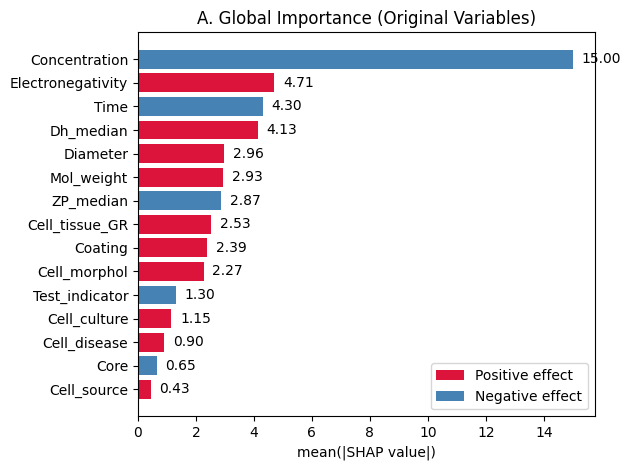

In [79]:
# 4. global importance on the aggregated vars
global_imp_agg = shap_aggr.abs().mean().sort_values(ascending=False)
global_mean_agg = shap_aggr.mean()  

# 5. assign color: red = positive effect, blue = negative effect
colors = ['crimson' if global_mean_agg[var] >= 0 else 'steelblue' 
          for var in global_imp_agg.index]

# — Plot A: Global attribute importance (aggregated vars) —
#plt.figure(figsize=(6,4))
plt.barh(global_imp_agg.index, global_imp_agg.values, color=colors)
plt.gca().invert_yaxis()
plt.title('A. Global Importance (Original Variables)')
plt.xlabel('mean(|SHAP value|)')
for i, v in enumerate(global_imp_agg.values):
    plt.text(v + global_imp_agg.max()*0.02, i, f"{v:.2f}", va='center')

# 6. add a legend
legend_elements = [Patch(facecolor='crimson',  label='Positive effect'),
                   Patch(facecolor='steelblue', label='Negative effect')]
plt.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()

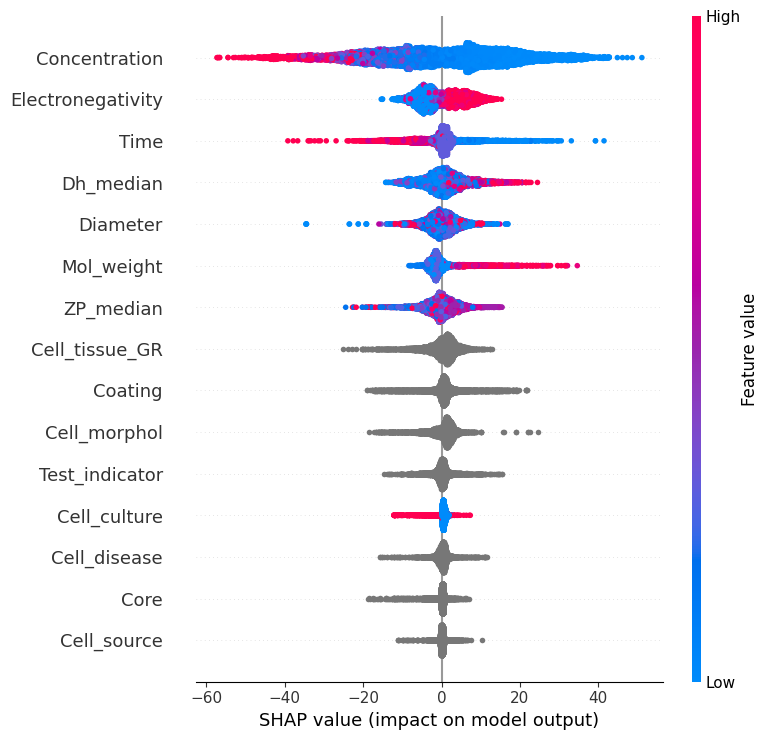

<Figure size 640x480 with 0 Axes>

In [80]:
# — Plot B: Local beeswarm for aggregated vars —
X_aggr = Viability.copy()

# create coating column by summing all "is_" variables
coating_vars = [c for c in Cytotox.columns if c.startswith("is_")]
# Get the coating name(s) for each row
X_aggr["Coating"] = X_aggr[coating_vars].apply(
    lambda row: ', '.join([col.replace('is_', '') for col in coating_vars if row[col] == 1]),
    axis=1
)

# drop original coating columns
X_aggr = X_aggr.drop(columns=coating_vars)

shap.summary_plot(
    shap_aggr.values,
    X_aggr[shap_aggr.columns], 
    feature_names=shap_aggr.columns.tolist(),
    plot_type='dot'
)
plt.tight_layout()
plt.show()

In [81]:
# build an Explanation for those variables
expl_agg = shap.Explanation(
  values=shap_aggr.values,
  base_values=explainer.expected_value,    # or whatever your baseline is
  data=X_aggr[shap_aggr.columns].values,
  feature_names=shap_aggr.columns.tolist()
)

/tmp/ipykernel_1724063/3219663622.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cax.set_yticklabels([f'{10**t:.3g}' for t in ticks])
/tmp/ipykernel_1724063/3219663622.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cax.set_yticklabels([f'{10**t:.3g}' for t in ticks])
/tmp/ipykernel_1724063/3219663622.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cax.set_yticklabels([f'{10**t:.3g}' for t in ticks])
/tmp/ipykernel_1724063/3219663622.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cax.set_yticklabels([f'{10**t:.3g}' for t in ticks])
/tmp/ipykernel_1724063/3219663622.py:27: UserWarning: set_ticklabels() should only be used with a fixed 

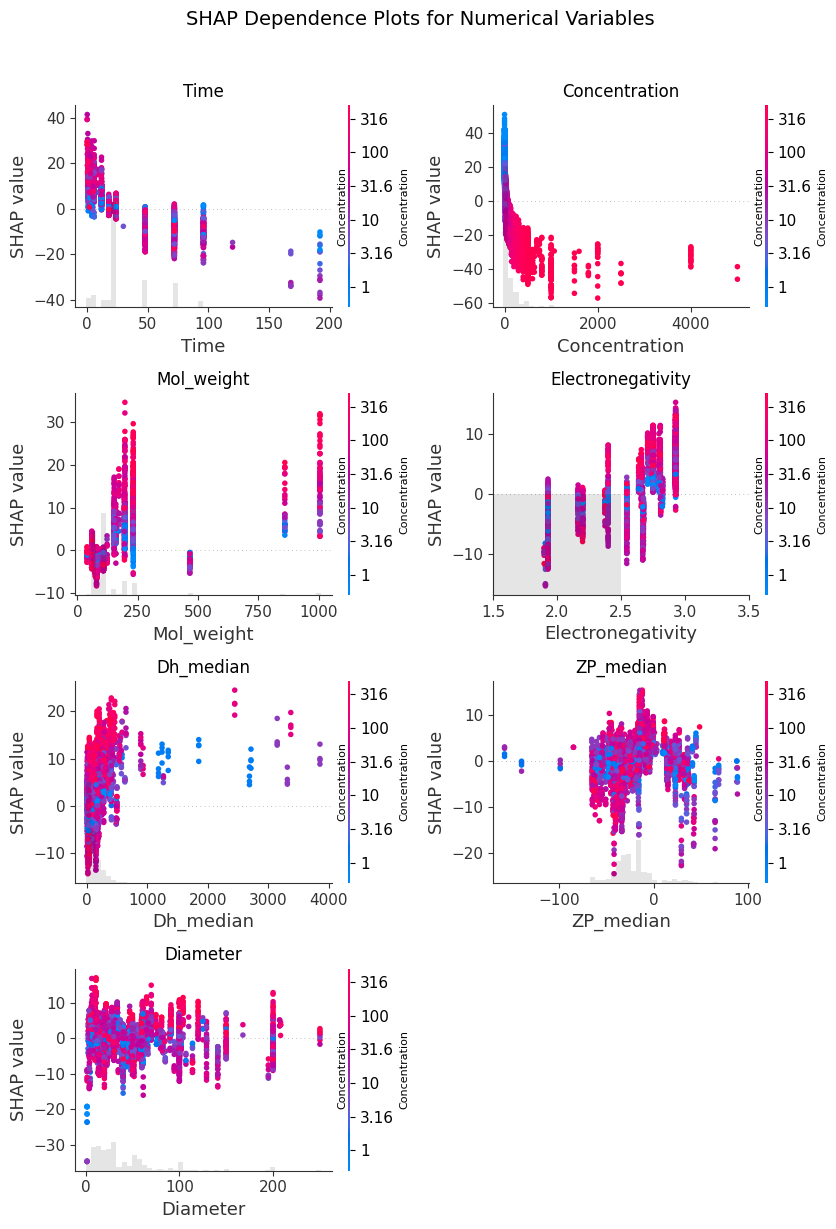

In [82]:
import copy

fig, axes = plt.subplots(4, 2, figsize=(8.5, 12))
axes = axes.flatten()

# log-transform concentration for coloring only (doesn't affect SHAP values/x-axis)
conc_log = copy.deepcopy(expl_agg[:, 'Concentration'])
conc_log.data = np.log10(conc_log.data.astype(float))

for i, var in enumerate(num_vars):
    n_axes_before = len(fig.axes)
    shap.plots.scatter(
        expl_agg[:, var],
        color=conc_log,
        ax=axes[i],
        show=False
    )
    axes[i].set_title(var)
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('SHAP value')

    # relabel the colorbar shap just created, converting log ticks back to real units
    new_axes = [a for a in fig.axes[n_axes_before:] if a not in axes]
    for cax in new_axes:
        cax.set_ylabel('Concentration', fontsize=8)
        ticks = cax.get_yticks()
        cax.set_yticklabels([f'{10**t:.3g}' for t in ticks])

for j in range(len(num_vars), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('SHAP Dependence Plots for Numerical Variables', fontsize=14, y=1.02)
plt.tight_layout()

plt.show()

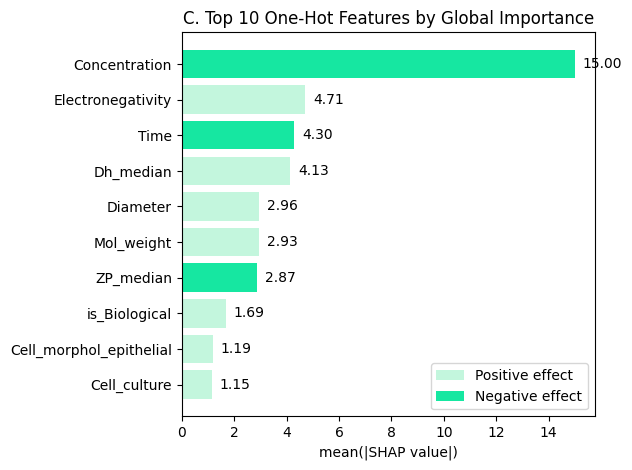

In [83]:
# 5. Now plot top-10 one-hot features globally
global_imp_onehot = pd.Series(
    np.abs(shap_vals).mean(axis=0),
    index=features
).sort_values(ascending=False)

# Signed mean (direction)
global_mean_onehot = pd.Series(
    shap_vals.mean(axis=0),
    index=features
)
top10_onehot = global_imp_onehot.head(10)

# Assign color by direction
colors = ['#C3F6DD' if global_mean_onehot[feat] >= 0 else '#16E7A1'
          for feat in top10_onehot.index]

plt.barh(top10_onehot.index, top10_onehot.values, color=colors)
plt.gca().invert_yaxis()
plt.title('C. Top 10 One-Hot Features by Global Importance')
plt.xlabel('mean(|SHAP value|)')
for i, v in enumerate(top10_onehot.values):
    plt.text(v + top10_onehot.max()*0.02, i, f"{v:.2f}", va='center')
legend_elements = [Patch(facecolor='#C3F6DD', label='Positive effect'),
                   Patch(facecolor='#16E7A1', label='Negative effect')]
plt.legend(handles=legend_elements, loc='lower right')    
plt.tight_layout()
plt.show()

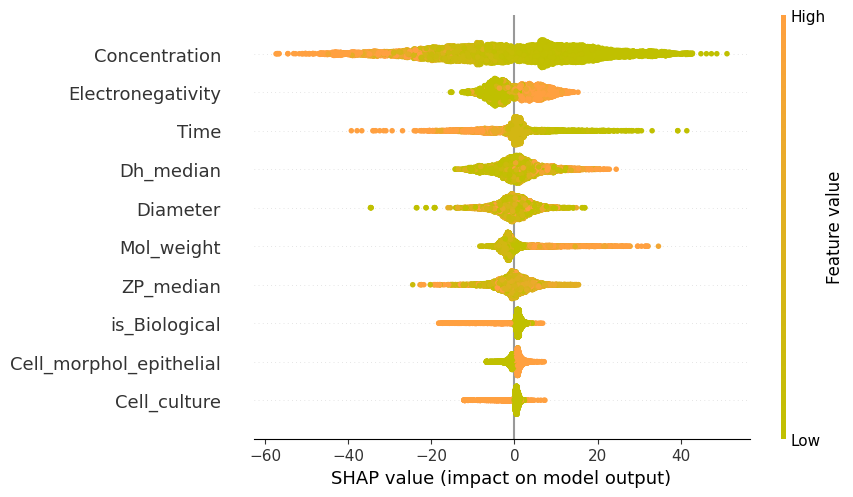

<Figure size 640x480 with 0 Axes>

In [84]:
# 6. pick out top-10 one-hot names & their integer positions
cols    = top10_onehot.index.tolist()
col_idx = [features.index(c) for c in cols]

# load the custom colormap
cmap = load_cmap("candy_soft", reverse=True, keep_first_n=2, cmap_type="continuous")
#cmap = load_cmap("Pastel", keep_first_n=2, cmap_type="continuous")
#cmap = load_cmap("Everglades", keep_first_n=4, cmap_type="continuous")
#cmap = load_cmap("Parupeneus_insularis", keep_first_n=2, cmap_type="continuous")

# build the Explanation object as before
expl_top10 = shap.Explanation(
    values=shap_vals[:, col_idx],
    base_values=explainer.expected_value,
    feature_names=cols,
    data=rX[cols].values
)

# pass it into the ‘color’ argument
shap.plots.beeswarm(
    expl_top10,
    max_display=10,
    color=cmap
)
plt.tight_layout()
plt.show()

In [85]:
rX.iloc[2011].values  # Gul et al. (2021)	2012	97	10.1016/j.taap.2011.12.020

array([  0.        ,  14.23      ,  72.        , 100.        ,
        60.083     ,   2.92666667,   1.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        , 128.        , -25.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   1.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   1.        ,   0.        ,   1.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.  

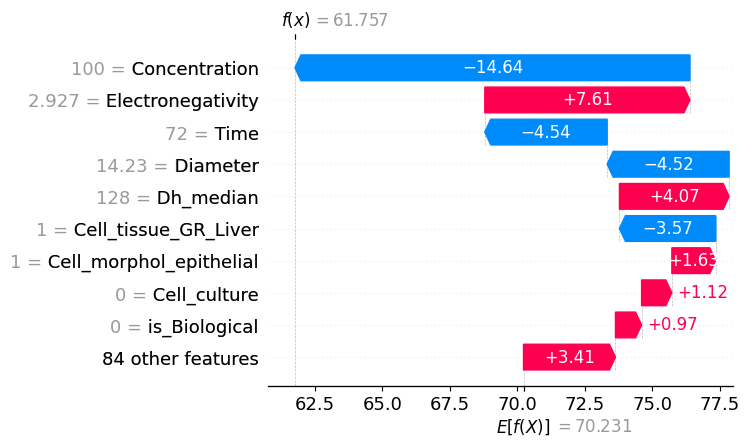

In [86]:
# pick a single example index
i = 2011    # true: 63.816%

# build an Explanation for that one instance
expl_single = shap.Explanation(
    values      = shap_vals[i],               
    base_values = explainer.expected_value,   
    data        = rX.iloc[i].values,           
    feature_names = rX.columns.tolist()
)

# Create the SHAP waterfall plot without immediately showing it
shap.plots.waterfall(expl_single, max_display=10, show=False)

# Grab the current figure and save it to file
fig = plt.gcf()
fig.set_size_inches(6, 4.5)    # modify it

plt.show()

# Applicability Domain

In [87]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

def williams_plot(X_train, X_test, y_train_true, y_train_pred,
                  y_test_true, y_test_pred,
                  num_vars, cat_vars,
                  model_name="Model"):
    """
    Williams Plot for Applicability Domain assessment.
    Scales only continuous features; binary/one-hot features passed through as-is.
    """

    # ── 1. Scale continuous only, passthrough binary ──────────────────────
    # Identify one-hot encoded columns (all binary columns not in cat_vars)
    binary_cols = [col for col in X_train.columns
                   if col not in num_vars]  # everything except continuous

    preprocessor = ColumnTransformer(transformers=[
        ('scale',       StandardScaler(), num_vars),
        ('passthrough', 'passthrough',    binary_cols)
    ])

    X_train_scaled = preprocessor.fit_transform(X_train)
    X_test_scaled  = preprocessor.transform(X_test)

    print(f"  Continuous features scaled : {len(num_vars)}")
    print(f"  Binary features kept as-is : {len(binary_cols)}")
    print(f"  Total features             : {X_train_scaled.shape[1]}")

    # ── 2. Leverage (hat matrix diagonal) ────────────────────────────────
    XtX_inv = np.linalg.pinv(X_train_scaled.T @ X_train_scaled)

    def compute_leverage(X, XtX_inv):
        return np.array([x @ XtX_inv @ x.T for x in X])

    h_train = compute_leverage(X_train_scaled, XtX_inv)
    h_test  = compute_leverage(X_test_scaled,  XtX_inv)

    # ── 3. Warning leverage threshold h* ──────────────────────────────────
    p = X_train_scaled.shape[1]
    n = X_train_scaled.shape[0]
    h_star = 3 * (p + 1) / n
    print(f"\n  h* (warning leverage) = {h_star:.4f}")
    print(f"  p (features) = {p}, n (training samples) = {n}")

    # ── 4. Standardized residuals ─────────────────────────────────────────
    def std_residuals(y_true, y_pred):
        residuals = np.array(y_true) - np.array(y_pred)
        sigma = np.std(residuals, ddof=1)
        return residuals / sigma

    sr_train = std_residuals(y_train_true, y_train_pred)
    sr_test  = std_residuals(y_test_true,  y_test_pred)

    # ── 5. AD flagging ────────────────────────────────────────────────────
    def flag_ad(h, sr, h_star):
        flags = []
        for hi, sri in zip(h, sr):
            if hi <= h_star and abs(sri) <= 3:
                flags.append("Inside AD")
            elif hi > h_star and abs(sri) <= 3:
                flags.append("High Leverage")
            elif hi <= h_star and abs(sri) > 3:
                flags.append("Response Outlier")
            else:
                flags.append("Outside AD")
        return flags

    flags_train = flag_ad(h_train, sr_train, h_star)
    flags_test  = flag_ad(h_test,  sr_test,  h_star)

    # ── 6. Summary ────────────────────────────────────────────────────────
    n_test = len(y_test_true)
    print(f"\n{'='*55}")
    print(f"  {model_name} — Applicability Domain Summary")
    print(f"{'='*55}")
    print(f"\n  INTERNAL DATA (n={n}):")
    for flag in ["Inside AD", "High Leverage", "Response Outlier", "Outside AD"]:
        count = flags_train.count(flag)
        print(f"    {flag:20s}: {count:4d} ({count/n*100:.1f}%)")

    print(f"\n  EXTERNAL DATA (n={n_test}):")
    for flag in ["Inside AD", "High Leverage", "Response Outlier", "Outside AD"]:
        count = flags_test.count(flag)
        print(f"    {flag:20s}: {count:4d} ({count/n_test*100:.1f}%)")

    # ── 7. Williams Plot ──────────────────────────────────────────────────
    color_map = {
        "Inside AD":        "#2ecc71",
        "High Leverage":    "#e74c3c",
        "Response Outlier": "#f39c12",
        "Outside AD":       "#772DE7"
    }

    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.22))
    fig.suptitle(f"Williams Plot — {model_name}",
                 fontsize=14, fontweight='bold')

    for idx, (ax, h, sr, flags, title) in enumerate(
        zip(
            axes,
            [h_train, h_test],
            [sr_train, sr_test],
            [flags_train, flags_test],
            ["Internal Data", "External Data"]
            )
        ):
        for flag, color in color_map.items():
            mask = [f == flag for f in flags]
            ax.scatter(
                np.array(h)[mask], np.array(sr)[mask],
                c=color, label=flag, alpha=0.7,
                edgecolors='white', linewidth=0.3, s=35
            )

        ax.axvline(x=h_star, color='black', linestyle='--',
                   linewidth=1.5, label=f'h* = {h_star:.3f}')
        ax.axhline(y= 3, color='gray', linestyle='--',
                   linewidth=1.5, label='±3σ')
        ax.axhline(y=-3, color='gray', linestyle='--', linewidth=1.5)

        ax.set_xlabel("Leverage (h)", fontsize=12)
        ax.set_ylabel("Standardized Residuals", fontsize=12)
        ax.set_title(title, fontsize=12)
        ax.legend(fontsize=9, loc='lower right')
        ax.grid(True, alpha=0.3)
        
        # legend only on the first subplot; remove from second
        if idx == 0:
            ax.legend(fontsize=9, loc='lower right')
        else:
            ax.legend().remove()

    plt.tight_layout()
    plt.savefig(f"williams_{model_name}.png", dpi=300, bbox_inches='tight')
    plt.show()

    # ── 8. Return flagged results ─────────────────────────────────────────
    df_results = pd.DataFrame({
        'Actual':       y_test_true,
        'Predicted':    y_test_pred,
        'Leverage':     h_test,
        'Std_Residual': sr_test,
        'AD_Flag':      flags_test
    })

    return df_results

  Continuous features scaled : 7
  Binary features kept as-is : 86
  Total features             : 93

  h* (warning leverage) = 0.0402
  p (features) = 93, n (training samples) = 7012

  XGB — Applicability Domain Summary

  INTERNAL DATA (n=7012):
    Inside AD           : 6544 (93.3%)
    High Leverage       :  296 (4.2%)
    Response Outlier    :  172 (2.5%)
    Outside AD          :    0 (0.0%)

  EXTERNAL DATA (n=1327):
    Inside AD           :  930 (70.1%)
    High Leverage       :  383 (28.9%)
    Response Outlier    :   10 (0.8%)
    Outside AD          :    4 (0.3%)


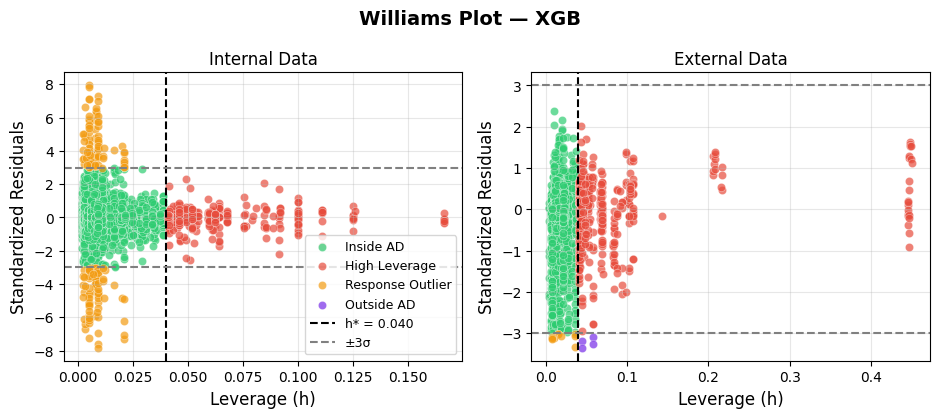

In [88]:
cat_vars = ["Core", "Test_indicator", "is_Unmodified", "is_Biological", "is_PEG_Polymer", "is_FuncGroup",
            "is_Silica_Inorganic", "is_Lipid_Bile_Acid", "is_Carbohydrate", "is_Nucleic_Peptide_AA",
            "Cell_morphol", "Cell_disease", "Cell_source", "Cell_culture", "Cell_tissue_GR"]
num_vars = ['Time', 'Concentration', 'Mol_weight', 'Electronegativity', 'Dh_median', 'ZP_median', 'Diameter']

df_results_XGB = williams_plot(
    X_train      = rX,         # Internal data
    X_test       = EX,         # external features
    y_train_true = rY,         # Internal actual viability
    y_train_pred = y_pred_cv,  # XGB predictions on Internal DATA
    y_test_true  = ERY,        # actual external viability
    y_test_pred  = Ey_pred,    # XGB predictions on external set
    num_vars     = num_vars,
    cat_vars     = cat_vars,
    model_name   = "XGB"
)